# Analisis Sentimen Ulasan Mobile Legends: Bang Bang (MLBB)
**Latar Belakang**:

MLBB adalah salah satu aplikasi game mobile populer dengan jumlah pengguna dan ulasan yang besar di Google Play Store. Ulasan tersebut memuat beragam tanggapan pengguna, mulai dari apresiasi, keluhan, hingga kritik terhadap berbagai aspek permainan. Keragaman tanggapan tersebut dapat menjadi sumber data untuk mengetahui kecenderungan sentimen pengguna terhadap MLBB. Oleh karena itu, dilakukan analisis sentimen sebagai salah satu bentuk penerapan Natural Language Processing (NLP) untuk mengidentifikasi dan mengklasifikasikan kecenderungan sentimen yang terdapat dalam ulasan pengguna.

**Tujuan**:
1. Menganalisis karakteristik ulasan MLBB yang telah diperoleh dari Google Play Store.
2. Memberikan label sentimen berdasarkan isi ulasan pengguna.
3. Membangingkan beberapa pendekatan untuk memperoleh model dengan performa baik.


### Deskripsi Dataset

Dataset diproses melalui Python Notebook `01_Scraping_Code_HannaMalika.ipynb` lewat library `google_play_scraper`. Dataset mentah yang dihasilkan tersebut disimpan dalam file `MLBB_scraped_reviews.csv` berisi 207000 baris data. Informasi yang tersedia dalam dataset tersebut di antaranya:
* `reviewId`: identitas ulasan.
* `userName`: nama pengguna yang memberikan ulasan.
* `userImage`: URL gambar profil pengguna.
* `content`: isi ulasan pengguna
* `score`: skor penilaian yang diberikan pengguna.
* `thumbsUpCount`: jumlah pengguna lain yang memberikan tanda "suka" terhadap ulasan tersebut.
* `reviewCreatedVersion`: versi aplikasi yang digunakan ketika ulasan dibaut.
* `at`: waktu ulasan dibuat.
* `replyContent`: isi balasan dari pengembang terhadap ulasan.
* `repliedAt`: waktu/tanggal ketika pengembangan memberikan balasan.
* `appVersion`: versi aplikasi yang berkaitan dengan ulasan.

## 01. IMPORT LIBRARY

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import re
import csv
import requests
from collections import Counter
from io import StringIO
from wordcloud import WordCloud # buat visualisasi bentuk awan kata (word cloud) dari teks
import time

import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
# from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
  

from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer # TF-IDF, BoW
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, ConfusionMatrixDisplay)


In [25]:
# Konfigurasi pandas
pd.options.mode.chained_assignment = None  # Menonaktifkan peringatan chaining
SEED = 0
np.random.seed(SEED)  # Mengatur seed untuk reproduktibilitas

# Konfigurasi NLTK
for res in ['punkt', 'punkt_tab', 'stopwords']:
    nltk.download(res)

# pd.set_option('display.max_colwidth', None)


[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Hanna\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Hanna\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Hanna\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


## 02. LOAD DATASET

In [26]:
df = pd.read_csv('MLBB_scraped_reviews.csv')
df.head()


,reviewId,userName,userImage,content,score,thumbsUpCount,reviewCreatedVersion,at,replyContent,repliedAt,appVersion
0,b3a7292e-c838-44c9-8596-69df28598018,Pengguna Google,https://play-lh.googleusercontent.com/EGemoI2N...,Selalu saja drop jaringan yang parah ketika ma...,1,8,2.2.16.12322,2026-09-17 18:57:09,NaN,NaN,2.2.16.12322
1,b318177b-6945-4db6-850e-4c0602f1ebf4,Pengguna Google,https://play-lh.googleusercontent.com/EGemoI2N...,"banyak dark system, matchmaking ngawur, banyak...",1,5,2.2.16.12322,2026-09-17 23:29:01,"Halo Kak,\nKami berkomitmen untuk menciptakan ...",2026-06-11 14:17:20,2.2.16.12322
2,e185838d-f5a3-4cbe-9aea-ea9ae9829341,Pengguna Google,https://play-lh.googleusercontent.com/EGemoI2N...,dari sekian lama permasalahan game ini masi be...,1,9,2.2.16.12322,2026-09-18 04:30:24,NaN,NaN,2.2.16.12322
3,26494ccf-b7fe-4b1e-b52d-87ab67730c7e,Pengguna Google,https://play-lh.googleusercontent.com/EGemoI2N...,menurutku gamenya bagus(tapi ga keren) dan unt...,1,9,2.2.16.12322,2026-09-16 18:32:05,NaN,NaN,2.2.16.12322
4,3b247e6c-e018-473b-89ba-0f3702ba5317,Pengguna Google,https://play-lh.googleusercontent.com/EGemoI2N...,"Tolonglah tun optimasi gamenya lebih baik lgi,...",3,6,2.2.16.12322,2026-09-18 21:27:03,NaN,NaN,2.2.16.12322


## 03. EDA

In [27]:
# Ukuran dataset
print(f"Jumlah baris: {df.shape[0]}")
print(f"Jumlah kolom: {df.shape[1]}\n")

# Menampilkan informasi dasar DataFrame
df.info()


Jumlah baris: 207000
Jumlah kolom: 11

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 207000 entries, 0 to 206999
Data columns (total 11 columns):
 #   Column                Non-Null Count   Dtype 
---  ------                --------------   ----- 
 0   reviewId              207000 non-null  object
 1   userName              207000 non-null  object
 2   userImage             207000 non-null  object
 3   content               207000 non-null  object
 4   score                 207000 non-null  int64 
 5   thumbsUpCount         207000 non-null  int64 
 6   reviewCreatedVersion  159867 non-null  object
 7   at                    207000 non-null  object
 8   replyContent          16145 non-null   object
 9   repliedAt             16145 non-null   object
 10  appVersion            159867 non-null  object
dtypes: int64(2), object(9)
memory usage: 17.4+ MB


In [28]:
# Cek data NaN dan duplikat DataFrame
print(f"Jumlah data NaN:\n{df.isnull().sum()}")
print(f"\nJumlah data duplikat: {df.duplicated(['content']).sum()}")


Jumlah data NaN:
reviewId                     0
userName                     0
userImage                    0
content                      0
score                        0
thumbsUpCount                0
reviewCreatedVersion     47133
at                           0
replyContent            190855
repliedAt               190855
appVersion               47133
dtype: int64

Jumlah data duplikat: 635


## 04. CLEANING DATA

In [29]:
print(f"Jumlah data awal                 : {len(df)}")

# Menghapus data NaN
df_clean = df.dropna(subset=['content', 'score'])
print(f"Jumlah data setelah drop NaN     : {len(df_clean)}")

# Menghapus data duplikat
df_clean = df_clean.drop_duplicates(subset=['content'])
print(f"Jumlah data setelah drop duplikat: {len(df_clean)}\n")

# Menampilkan informasi dasar DataFrame setelah pembersihan
df_clean.info()  


Jumlah data awal                 : 207000
Jumlah data setelah drop NaN     : 207000
Jumlah data setelah drop duplikat: 206365

<class 'pandas.core.frame.DataFrame'>
Index: 206365 entries, 0 to 206999
Data columns (total 11 columns):
 #   Column                Non-Null Count   Dtype 
---  ------                --------------   ----- 
 0   reviewId              206365 non-null  object
 1   userName              206365 non-null  object
 2   userImage             206365 non-null  object
 3   content               206365 non-null  object
 4   score                 206365 non-null  int64 
 5   thumbsUpCount         206365 non-null  int64 
 6   reviewCreatedVersion  159256 non-null  object
 7   at                    206365 non-null  object
 8   replyContent          16142 non-null   object
 9   repliedAt             16142 non-null   object
 10  appVersion            159256 non-null  object
dtypes: int64(2), object(9)
memory usage: 18.9+ MB


## 05. TEXT PREPROCESSING

1. `cleaningText`: hapus link, mention, hashtag, RT (retweet), tautan (link), newline menjadi spasi, dan spasi berlebih.
2. `casefoldingText`: konversi karakter teks ke huruf kecil (lowercase).
3. `fix_slangwords`: kata gaul mnejadi kata baku
4. `tokenizingText`: membagi teks menjadi daftar kata (token).
5. `filteringText`: hapus stopwords.
6. `toSentence`: gabungkan token menjadi satu teks utuh.

In [30]:
slangwords = {"@": "di", "abis": "habis", "wtb": "beli", "masi": "masih", "wts": "jual", "wtt": "tukar", "bgt": "banget", "maks": "maksimal", "plisss": "tolong", "bgttt": "banget", "indo": "indonesia", "bgtt": "banget", "ad": "ada", "rv": "redvelvet", "plis": "tolong", "pls": "tolong", "cr": "sumber", "cod": "bayar ditempat", "adlh": "adalah", "afaik": "as far as i know", "ahaha": "haha", "aj": "saja", "ajep-ajep": "dunia gemerlap", "ak": "saya", "akika": "aku", "akkoh": "aku", "akuwh": "aku", "alay": "norak", "alow": "halo", "ambilin": "ambilkan", "ancur": "hancur", "anjrit": "anjing", "anter": "antar", "ap2": "apa-apa", "apasih": "apa sih", "apes": "sial", "aps": "apa", "aq": "saya", "aquwh": "aku", "asbun": "asal bunyi", "aseekk": "asyik", "asekk": "asyik", "asem": "asam", "aspal": "asli tetapi palsu", "astul": "asal tulis", "ato": "atau", "au ah": "tidak mau tahu", "awak": "saya", "ay": "sayang", "ayank": "sayang", "b4": "sebelum", "bakalan": "akan", "bandes": "bantuan desa", "bangedh": "banget", "banpol": "bantuan polisi", "banpur": "bantuan tempur", "basbang": "basi", "bcanda": "bercanda", "bdg": "bandung", "begajulan": "nakal", "beliin": "belikan", "bencong": "banci", "bentar": "sebentar", "ber3": "bertiga", "beresin": "membereskan", "bete": "bosan", "beud": "banget", "bg": "abang", "bgmn": "bagaimana", "bijimane": "bagaimana", "bintal": "bimbingan mental", "bkl": "akan", "bknnya": "bukannya", "blegug": "bodoh", "blh": "boleh", "bln": "bulan", "blum": "belum", "bnci": "benci", "bnran": "yang benar", "bodor": "lucu", "bokap": "ayah", "boker": "buang air besar", "bokis": "bohong", "boljug": "boleh juga", "bonek": "bocah nekat", "boyeh": "boleh", "br": "baru", "brg": "bareng", "bro": "saudara laki-laki", "bru": "baru", "bs": "bisa", "bsen": "bosan", "bt": "buat", "btw": "ngomong-ngomong", "buaya": "tidak setia", "bubbu": "tidur", "bubu": "tidur", "bumil": "ibu hamil", "bw": "bawa", "bwt": "buat", "byk": "banyak", "byrin": "bayarkan", "cabal": "sabar", "cadas": "keren", "calo": "makelar", "can": "belum", "capcus": "pergi", "caper": "cari perhatian", "ce": "cewek", "cekal": "cegah tangkal", "cemen": "penakut", "cengengesan": "tertawa", "cepet": "cepat", "cew": "cewek", "chuyunk": "sayang", "cimeng": "ganja", "cipika cipiki": "cium pipi kanan cium pipi kiri", "ciyh": "sih", "ckepp": "cakep", "ckp": "cakep", "cmiiw": "correct me if i'm wrong", "cmpur": "campur", "cong": "banci", "conlok": "cinta lokasi", "cowwyy": "maaf", "cp": "siapa", "cpe": "capek", "cppe": "capek", "cucok": "cocok", "cuex": "cuek", "cumi": "Cuma miscall", "cups": "culun", "curanmor": "pencurian kendaraan bermotor", "curcol": "curahan hati colongan", "cwek": "cewek", "cyin": "cinta", "d": "di", "dah": "deh", "dapet": "dapat", "de": "adik", "dek": "adik", "demen": "suka", "deyh": "deh", "dgn": "dengan", "diancurin": "dihancurkan", "dimaafin": "dimaafkan", "dimintak": "diminta", "disono": "di sana", "dket": "dekat", "dkk": "dan kawan-kawan", "dll": "dan lain-lain", "dlu": "dulu", "dngn": "dengan", "dodol": "bodoh", "doku": "uang", "dongs": "dong", "dpt": "dapat", "dri": "dari", "drmn": "darimana", "drtd": "dari tadi", "dst": "dan seterusnya", "dtg": "datang", "duh": "aduh", "duren": "durian", "ed": "edisi", "egp": "emang gue pikirin", "eke": "aku", "elu": "kamu", "emangnya": "memangnya", "emng": "memang", "endak": "tidak", "enggak": "tidak", "envy": "iri", "ex": "mantan", "fax": "facsimile", "fifo": "first in first out", "folbek": "follow back", "fyi": "sebagai informasi", "gaada": "tidak ada uang", "gag": "tidak", "gaje": "tidak jelas", "gak papa": "tidak apa-apa", "papa": "apa-apa", "gan": "juragan", "gaptek": "gagap teknologi", "gatek": "gagap teknologi", "gawe": "kerja", "gbs": "tidak bisa", "gebetan": "orang yang disuka", "geje": "tidak jelas", "gepeng": "gelandangan dan pengemis", "ghiy": "lagi", "gile": "gila", "gimana": "bagaimana", "gino": "gigi nongol", "githu": "gitu", "gj": "tidak jelas", "gmana": "bagaimana", "gn": "begini", "goblok": "bodoh", "golput": "golongan putih", "gowes": "mengayuh sepeda", "gpny": "tidak punya", "gr": "gede rasa", "gretongan": "gratisan", "gtau": "tidak tahu", "gua": "saya", "guoblok": "goblok", "gw": "saya", "ha": "tertawa", "haha": "tertawa", "hallow": "halo", "hankam": "pertahanan dan keamanan", "hehe": "he", "helo": "halo", "hey": "hai", "hlm": "halaman", "hny": "hanya", "hoax": "isu bohong", "hr": "hari", "hrus": "harus", "hubdar": "perhubungan darat", "huff": "mengeluh", "hum": "rumah", "humz": "rumah", "ilang": "hilang", "ilfil": "tidak suka", "imho": "in my humble opinion", "imoetz": "imut", "item": "hitam", "itungan": "hitungan", "iye": "iya", "ja": "saja", "jadiin": "jadi", "jaim": "jaga image", "jayus": "tidak lucu", "jdi": "jadi", "jem": "jam", "jga": "juga", "jgnkan": "jangankan", "jir": "anjing", "jln": "jalan", "jomblo": "tidak punya pacar", "jubir": "juru bicara", "jutek": "galak", "k": "ke", "kab": "kabupaten", "kabor": "kabur", "kacrut": "kacau", "kadiv": "kepala divisi", "kagak": "tidak", "kalo": "kalau", "kampret": "sialan", "kamtibmas": "keamanan dan ketertiban masyarakat", "kamuwh": "kamu", "kanwil": "kantor wilayah", "karna": "karena", "kasubbag": "kepala subbagian", "katrok": "kampungan", "kayanya": "kayaknya", "kbr": "kabar", "kdu": "harus", "kec": "kecamatan", "kejurnas": "kejuaraan nasional", "kekeuh": "keras kepala", "kel": "kelurahan", "kemaren": "kemarin", "kepengen": "mau", "kepingin": "mau", "kepsek": "kepala sekolah", "kesbang": "kesatuan bangsa", "kesra": "kesejahteraan rakyat", "ketrima": "diterima", "kgiatan": "kegiatan", "kibul": "bohong", "kimpoi": "kawin", "kl": "kalau", "klianz": "kalian", "kloter": "kelompok terbang", "klw": "kalau", "km": "kamu", "kmps": "kampus", "kmrn": "kemarin", "knal": "kenal", "knp": "kenapa", "kodya": "kota madya", "komdis": "komisi disiplin", "komsov": "komunis sovyet", "kongkow": "kumpul bareng teman-teman", "kopdar": "kopi darat", "korup": "korupsi", "kpn": "kapan", "krenz": "keren", "krm": "kirim", "kt": "kita", "ktmu": "ketemu", "ktr": "kantor", "kuper": "kurang pergaulan", "kw": "imitasi", "kyk": "seperti", "la": "lah", "lam": "salam", "lamp": "lampiran", "lanud": "landasan udara", "latgab": "latihan gabungan", "lebay": "berlebihan", "leh": "boleh", "lelet": "lambat", "lemot": "lambat", "lgi": "lagi", "lgsg": "langsung", "liat": "lihat", "litbang": "penelitian dan pengembangan", "lmyn": "lumayan", "lo": "kamu", "loe": "kamu", "lola": "lambat berfikir", "louph": "cinta", "low": "kalau", "lp": "lupa", "luber": "langsung, umum, bebas, dan rahasia", "luchuw": "lucu", "lum": "belum", "luthu": "lucu", "lwn": "lawan", "maacih": "terima kasih", "mabal": "bolos", "macem": "macam", "macih": "masih", "maem": "makan", "magabut": "makan gaji buta", "maho": "homo", "mak jang": "kaget", "maksain": "memaksa", "malem": "malam", "mam": "makan", "maneh": "kamu", "maniez": "manis", "mao": "mau", "masukin": "masukkan", "melu": "ikut", "mepet": "dekat sekali", "mgu": "minggu", "migas": "minyak dan gas bumi", "mikol": "minuman beralkohol", "miras": "minuman keras", "mlah": "malah", "mngkn": "mungkin", "mo": "mau", "mokad": "mati", "moso": "masa", "mpe": "sampai", "msk": "masuk", "mslh": "masalah", "mt": "makan teman", "mubes": "musyawarah besar", "mulu": "melulu", "mumpung": "selagi", "munas": "musyawarah nasional", "muntaber": "muntah dan berak", "musti": "mesti", "muupz": "maaf", "mw": "now watching", "n": "dan", "nanam": "menanam", "nanya": "bertanya", "napa": "kenapa", "napi": "narapidana", "napza": "narkotika, alkohol, psikotropika, dan zat adiktif ", "narkoba": "narkotika, psikotropika, dan obat terlarang", "nasgor": "nasi goreng", "nda": "tidak", "ndiri": "sendiri", "ne": "ini", "nekolin": "neokolonialisme", "nembak": "menyatakan cinta", "ngabuburit": "menunggu berbuka puasa", "ngaku": "mengaku", "ngambil": "mengambil", "nganggur": "tidak punya pekerjaan", "ngapah": "kenapa", "ngaret": "terlambat", "ngasih": "memberikan", "ngebandel": "berbuat bandel", "ngegosip": "bergosip", "ngeklaim": "mengklaim", "ngeksis": "menjadi eksis", "ngeles": "berkilah", "ngelidur": "menggigau", "ngerampok": "merampok", "ngga": "tidak", "ngibul": "berbohong", "ngiler": "mau", "ngiri": "iri", "ngisiin": "mengisikan", "ngmng": "bicara", "ngomong": "bicara", "ngubek2": "mencari-cari", "ngurus": "mengurus", "nie": "ini", "nih": "ini", "niyh": "nih", "nmr": "nomor", "nntn": "nonton", "nobar": "nonton bareng", "np": "now playing", "ntar": "nanti", "ntn": "nonton", "numpuk": "bertumpuk", "nutupin": "menutupi", "nyari": "mencari", "nyekar": "menyekar", "nyicil": "mencicil", "nyoblos": "mencoblos", "nyokap": "ibu", "ogah": "tidak mau", "ol": "online", "ongkir": "ongkos kirim", "oot": "out of topic", "org2": "orang-orang", "ortu": "orang tua", "otda": "otonomi daerah", "otw": "on the way, sedang di jalan", "pacal": "pacar", "pake": "pakai", "pala": "kepala", "pansus": "panitia khusus", "parpol": "partai politik", "pasutri": "pasangan suami istri", "pd": "pada", "pede": "percaya diri", "pelatnas": "pemusatan latihan nasional", "pemda": "pemerintah daerah", "pemkot": "pemerintah kota", "pemred": "pemimpin redaksi", "penjas": "pendidikan jasmani", "perda": "peraturan daerah", "perhatiin": "perhatikan", "pesenan": "pesanan", "pgang": "pegang", "pi": "tapi", "pilkada": "pemilihan kepala daerah", "pisan": "sangat", "pk": "penjahat kelamin", "plg": "paling", "pmrnth": "pemerintah", "polantas": "polisi lalu lintas", "ponpes": "pondok pesantren", "pp": "pulang pergi", "prg": "pergi", "prnh": "pernah", "psen": "pesan", "pst": "pasti", "pswt": "pesawat", "pw": "posisi nyaman", "qmu": "kamu", "rakor": "rapat koordinasi", "ranmor": "kendaraan bermotor", "re": "reply", "ref": "referensi", "rehab": "rehabilitasi", "rempong": "sulit", "repp": "balas", "restik": "reserse narkotika", "rhs": "rahasia", "rmh": "rumah", "ru": "baru", "ruko": "rumah toko", "rusunawa": "rumah susun sewa", "ruz": "terus", "saia": "saya", "salting": "salah tingkah", "sampe": "sampai", "samsek": "sama sekali", "sapose": "siapa", "satpam": "satuan pengamanan", "sbb": "sebagai berikut", "sbh": "sebuah", "sbnrny": "sebenarnya", "scr": "secara", "sdgkn": "sedangkan", "sdkt": "sedikit", "se7": "setuju", "sebelas dua belas": "mirip", "sembako": "sembilan bahan pokok", "sempet": "sempat", "sendratari": "seni drama tari", "sgt": "sangat", "shg": "sehingga", "siech": "sih", "sikon": "situasi dan kondisi", "sinetron": "sinema elektronik", "siramin": "siramkan", "sj": "saja", "skalian": "sekalian", "sklh": "sekolah", "skt": "sakit", "slesai": "selesai", "sll": "selalu", "slma": "selama", "slsai": "selesai", "smpt": "sempat", "smw": "semua", "sndiri": "sendiri", "soljum": "sholat jumat", "songong": "sombong", "sory": "maaf", "sosek": "sosial-ekonomi", "sotoy": "sok tahu", "spa": "siapa", "sppa": "siapa", "spt": "seperti", "srtfkt": "sertifikat", "stiap": "setiap", "stlh": "setelah", "suk": "masuk", "sumpek": "sempit", "syg": "sayang", "t4": "tempat", "tajir": "kaya", "tau": "tahu", "taw": "tahu", "td": "tadi", "tdk": "tidak", "teh": "kakak perempuan", "telat": "terlambat", "telmi": "telat berpikir", "temen": "teman", "tengil": "menyebalkan", "tepar": "terkapar", "tggu": "tunggu", "tgu": "tunggu", "thankz": "terima kasih", "thn": "tahun", "tilang": "bukti pelanggaran", "tipiwan": "TvOne", "tks": "terima kasih", "tlp": "telepon", "tls": "tulis", "tmbah": "tambah", "tmen2": "teman-teman", "tmpah": "tumpah", "tmpt": "tempat", "tngu": "tunggu", "tnyta": "ternyata", "tokai": "tai", "toserba": "toko serba ada", "tpi": "tapi", "trdhulu": "terdahulu", "trima": "terima kasih", "trm": "terima", "trs": "terus", "trutama": "terutama", "ts": "penulis", "tst": "tahu sama tahu", "ttg": "tentang", "tuch": "tuh", "tuir": "tua", "tw": "tahu", "u": "kamu", "ud": "sudah", "udah": "sudah", "ujg": "ujung", "ul": "ulangan", "unyu": "lucu", "uplot": "unggah", "urang": "saya", "usah": "perlu", "utk": "untuk", "valas": "valuta asing", "w/": "dengan", "wadir": "wakil direktur", "wamil": "wajib militer", "warkop": "warung kopi", "warteg": "warung tegal", "wat": "buat", "wkt": "waktu", "wtf": "what the fuck", "xixixi": "tertawa", "ya": "iya", "yap": "iya", "yaudah": "ya sudah", "yawdah": "ya sudah", "yg": "yang", "yl": "yang lain", "yo": "iya", "yowes": "ya sudah", "yup": "iya", "7an": "tujuan", "ababil": "abg labil", "acc": "accord", "adlah": "adalah", "adoh": "aduh", "aha": "tertawa", "aing": "saya", "aja": "saja", "ajj": "saja", "aka": "dikenal juga sebagai", "akko": "aku", "akku": "aku", "akyu": "aku", "aljasa": "asal jadi saja", "ama": "sama", "ambl": "ambil", "anjir": "anjing", "ank": "anak", "ap": "apa", "apaan": "apa", "ape": "apa", "aplot": "unggah", "apva": "apa", "aqu": "aku", "asap": "sesegera mungkin", "aseek": "asyik", "asek": "asyik", "aseknya": "asyiknya", "asoy": "asyik", "astrojim": "astagfirullahaladzim", "ath": "kalau begitu", "atuh": "kalau begitu", "ava": "avatar", "aws": "awas", "ayang": "sayang", "ayok": "ayo", "bacot": "banyak bicara", "bales": "balas", "bangdes": "pembangunan desa", "bangkotan": "tua", "banpres": "bantuan presiden", "bansarkas": "bantuan sarana kesehatan", "bazis": "badan amal, zakat, infak, dan sedekah", "bcoz": "karena", "beb": "sayang", "bejibun": "banyak", "belom": "belum", "bener": "benar", "ber2": "berdua", "berdikari": "berdiri di atas kaki sendiri", "bet": "banget", "beti": "beda tipis", "beut": "banget", "bgd": "banget", "bgs": "bagus", "bagu": "bagus", "bhubu": "tidur", "bimbuluh": "bimbingan dan penyuluhan", "bisi": "kalau-kalau", "bkn": "bukan", "bl": "beli", "blg": "bilang", "blm": "belum", "bls": "balas", "bnchi": "benci", "bngung": "bingung", "bnyk": "banyak", "bohay": "badan aduhai", "bokep": "porno", "bokin": "pacar", "bole": "boleh", "bolot": "bodoh", "bonyok": "ayah ibu", "bpk": "bapak", "brb": "segera kembali", "brngkt": "berangkat", "brp": "berapa", "brur": "saudara laki-laki", "bsa": "bisa", "bsk": "besok", "bu_bu": "tidur", "bubarin": "bubarkan", "buber": "buka bersama", "bujubune": "luar biasa", "buser": "buru sergap", "bwhn": "bawahan", "byar": "bayar", "byr": "bayar", "c8": "chat", "cabut": "pergi", "caem": "cakep", "cama-cama": "sama-sama", "cangcut": "celana dalam", "cape": "capek", "caur": "jelek", "cekak": "tidak ada uang", "cekidot": "coba lihat", "cemplungin": "cemplungkan", "ceper": "pendek", "ceu": "kakak perempuan", "cewe": "cewek", "cibuk": "sibuk", "cin": "cinta", "ciye": "cie", "ckck": "ck", "clbk": "cinta lama bersemi kembali", "cmpr": "campur", "cnenk": "senang", "congor": "mulut", "cow": "cowok", "coz": "karena", "cpa": "siapa", "gokil": "gila", "gombal": "suka merayu", "gpl": "tidak pakai lama", "gpp": "tidak apa-apa", "gretong": "gratis", "gt": "begitu", "gtw": "tidak tahu", "gue": "saya", "guys": "teman-teman", "gws": "cepat sembuh", "haghaghag": "tertawa", "hakhak": "tertawa", "handak": "bahan peledak", "hansip": "pertahanan sipil", "hellow": "halo", "helow": "halo", "hi": "hai", "hlng": "hilang", "hnya": "hanya", "houm": "rumah", "hrs": "harus", "hubad": "hubungan angkatan darat", "hubla": "perhubungan laut", "huft": "mengeluh", "humas": "hubungan masyarakat", "idk": "saya tidak tahu", "ilfeel": "tidak suka", "imba": "jago sekali", "imoet": "imut", "info": "informasi", "itung": "hitung", "isengin": "bercanda", "iyala": "iya lah", "iyo": "iya", "jablay": "jarang dibelai", "jadul": "jaman dulu", "jancuk": "anjing", "jd": "jadi", "jdikan": "jadikan", "jg": "juga", "jgn": "jangan", "jijay": "jijik", "jkt": "jakarta", "jnj": "janji", "jth": "jatuh", "jurdil": "jujur adil", "jwb": "jawab", "ka": "kakak", "kabag": "kepala bagian", "kacian": "kasihan", "kadit": "kepala direktorat", "kaga": "tidak", "kaka": "kakak", "kamtib": "keamanan dan ketertiban", "kamuh": "kamu", "kamyu": "kamu", "kapt": "kapten", "kasat": "kepala satuan", "kasubbid": "kepala subbidang", "kau": "kamu", "kbar": "kabar", "kcian": "kasihan", "keburu": "terlanjur", "kedubes": "kedutaan besar", "kek": "seperti", "keknya": "kayaknya", "keliatan": "kelihatan", "keneh": "masih", "kepikiran": "terpikirkan", "kepo": "mau tahu urusan orang", "kere": "tidak punya uang", "kesian": "kasihan", "ketauan": "ketahuan", "keukeuh": "keras kepala", "khan": "kan", "kibus": "kaki busuk", "kk": "kakak", "klian": "kalian", "klo": "kalau", "kluarga": "keluarga", "klwrga": "keluarga", "kmari": "kemari", "kmpus": "kampus", "kn": "kan", "knl": "kenal", "knpa": "kenapa", "kog": "kok", "kompi": "komputer", "komtiong": "komunis Tiongkok", "konjen": "konsulat jenderal", "koq": "kok", "kpd": "kepada", "kptsan": "keputusan", "krik": "garing", "krn": "karena", "ktauan": "ketahuan", "ktny": "katanya", "kudu": "harus", "kuq": "kok", "ky": "seperti", "kykny": "kayanya", "laka": "kecelakaan", "lambreta": "lambat", "lansia": "lanjut usia", "lapas": "lembaga pemasyarakatan", "lbur": "libur", "lekong": "laki-laki", "lg": "lagi", "lgkp": "lengkap", "lht": "lihat", "linmas": "perlindungan masyarakat", "lmyan": "lumayan", "lngkp": "lengkap", "loch": "loh", "lol": "tertawa", "lom": "belum", "loupz": "cinta", "lowh": "kamu", "lu": "kamu", "luchu": "lucu", "luff": "cinta", "luph": "cinta", "lw": "kamu", "lwt": "lewat", "maaciw": "terima kasih", "mabes": "markas besar", "macem-macem": "macam-macam", "madesu": "masa depan suram", "maen": "main", "mahatma": "maju sehat bersama", "mak": "ibu", "makasih": "terima kasih", "malah": "bahkan", "malu2in": "memalukan", "mamz": "makan", "manies": "manis", "mantep": "mantap", "markus": "makelar kasus", "mba": "mbak", "mending": "lebih baik", "mgkn": "mungkin", "mhn": "mohon", "miker": "minuman keras", "milis": "mailing list", "mksd": "maksud", "mls": "malas", "mnt": "minta", "moge": "motor gede", "mokat": "mati", "mosok": "masa", "msh": "masih", "mskpn": "meskipun", "msng2": "masing-masing", "muahal": "mahal", "muker": "musyawarah kerja", "mumet": "pusing", "muna": "munafik", "munaslub": "musyawarah nasional luar biasa", "musda": "musyawarah daerah", "muup": "maaf", "muuv": "maaf", "nal": "kenal", "nangis": "menangis", "naon": "apa", "napol": "narapidana politik", "naq": "anak", "narsis": "bangga pada diri sendiri", "nax": "anak", "ndak": "tidak", "ndut": "gendut", "nekolim": "neokolonialisme", "nelfon": "menelepon", "ngabis2in": "menghabiskan", "ngakak": "tertawa", "ngambek": "marah", "ngampus": "pergi ke kampus", "ngantri": "mengantri", "ngapain": "sedang apa", "ngaruh": "berpengaruh", "ngawur": "berbicara sembarangan", "ngeceng": "kumpul bareng-bareng", "ngeh": "sadar", "ngekos": "tinggal di kos", "ngelamar": "melamar", "ngeliat": "melihat", "ngemeng": "bicara terus-terusan", "ngerti": "mengerti", "nggak": "tidak", "ngikut": "ikut", "nginep": "menginap", "ngisi": "mengisi", "ngmg": "bicara", "ngocol": "lucu", "ngomongin": "membicarakan", "ngumpul": "berkumpul", "ni": "ini", "nyasar": "tersesat", "nyariin": "mencari", "nyiapin": "mempersiapkan", "nyiram": "menyiram", "nyok": "ayo", "o/": "oleh", "ok": "ok", "priksa": "periksa", "pro": "profesional", "psn": "pesan", "psti": "pasti", "puanas": "panas", "qmo": "kamu", "qt": "kita", "rame": "ramai", "raskin": "rakyat miskin", "red": "redaksi", "reg": "register", "rejeki": "rezeki", "renstra": "rencana strategis", "reskrim": "reserse kriminal", "sni": "sini", "somse": "sombong sekali", "sorry": "maaf", "sosbud": "sosial-budaya", "sospol": "sosial-politik", "sowry": "maaf", "spd": "sepeda", "sprti": "seperti", "spy": "supaya", "stelah": "setelah", "subbag": "subbagian", "sumbangin": "sumbangkan", "sy": "saya", "syp": "siapa", "tabanas": "tabungan pembangunan nasional", "tar": "nanti", "taun": "tahun", "tawh": "tahu", "tdi": "tadi", "te2p": "tetap", "tekor": "rugi", "telkom": "telekomunikasi", "telp": "telepon", "temen2": "teman-teman", "tengok": "menjenguk", "terbitin": "terbitkan", "tgl": "tanggal", "thanks": "terima kasih", "thd": "terhadap", "thx": "terima kasih", "tipi": "TV", "tkg": "tukang", "tll": "terlalu", "tlpn": "telepon", "tman": "teman", "tmbh": "tambah", "tmn2": "teman-teman", "tmph": "tumpah", "tnda": "tanda", "tnh": "tanah", "togel": "toto gelap", "tp": "tapi", "tq": "terima kasih", "trgntg": "tergantung", "trims": "terima kasih", "cb": "coba", "y": "ya", "munfik": "munafik", "reklamuk": "reklamasi", "sma": "sama", "tren": "trend", "ngehe": "kesal", "mz": "mas", "analisise": "analisis", "sadaar": "sadar", "sept": "september", "nmenarik": "menarik", "zonk": "bodoh", "rights": "benar", "simiskin": "miskin", "ngumpet": "sembunyi", "hardcore": "keras", "akhirx": "akhirnya", "solve": "solusi", "watuk": "batuk", "ngebully": "intimidasi", "masy": "masyarakat", "still": "masih", "tauk": "tahu", "mbual": "bual", "tioghoa": "tionghoa", "ngentotin": "senggama", "kentot": "senggama", "faktakta": "fakta", "sohib": "teman", "rubahnn": "rubah", "trlalu": "terlalu", "nyela": "cela", "heters": "pembenci", "nyembah": "sembah", "most": "paling", "ikon": "lambang", "light": "terang", "pndukung": "pendukung", "setting": "atur", "seting": "akting", "next": "lanjut", "waspadalah": "waspada", "gantengsaya": "ganteng", "parte": "partai", "nyerang": "serang", "nipu": "tipu", "ktipu": "tipu", "jentelmen": "berani", "buangbuang": "buang", "tsangka": "tersangka", "kurng": "kurang", "ista": "nista", "less": "kurang", "koar": "teriak", "paranoid": "takut", "problem": "masalah", "tahi": "kotoran", "tirani": "tiran", "tilep": "tilap", "happy": "bahagia", "tak": "tidak", "penertiban": "tertib", "uasai": "kuasa", "mnolak": "tolak", "trending": "trend", "taik": "tahi", "wkwkkw": "tertawa", "ahokncc": "ahok", "istaa": "nista", "benarjujur": "jujur", "mgkin": "mungkin", "tlg": "tolong", "tlng": "tolong", "udh": "sudah", "sdh": "sudah", "gem": "game", 'ga': 'tidak', "gk" : "tidak", "monton" : "moonton", "ton" : "moonton", "tun" : "moonton", "gede": "besar", "ckup" : "cukup", "buduk": "buruk", "nambah": "tambah", "dak": "tidak", "kayak": "seperti", "toxit": "toxic", 'knpa': 'kenapa', 'melulu': 'selalu', 'gim': 'game', 'makin' : 'semakin', 'ngelag': 'lag', 'pdhl': 'padahal', 'kdg': 'kadang', 'trakhir': 'terakhir', 'cma': 'cuma', 'kompe': 'kompetitif', 'hllo': 'halo', 'gabisa': 'tidak bisa', 'gajelas': 'tidak jelas', 'gak': 'tidak', 'gapapa': 'tidak apa-apa', 'wort': 'worth', 'pas': 'saat', 'anj': 'anjing', 'mayan': 'lumayan', 'pliss': 'tolong', 'anjay': 'anjing', 'pencet': 'tekan', 'pake': 'pakai', 'muntun': 'moonton'}

def fix_slangwords(text):
    return ' '.join(slangwords.get(w, w) for w in text.split())


In [ ]:
def cleaningText(text):
    text = str(text)
    text = re.sub(r'http\S+|www\S+', '', text) # hapus URL
    text = re.sub(r'@(\w+)', r'\1', text)      # hapus mention
    text = re.sub(r'#(\w+)', r'\1', text)      # hapus hashtag tetapi mempertahankan katanya
    text = re.sub(r'\d+', '', text)            # hapus angka
    text = re.sub(r'\bRT\b', ' ', text)        # RT sebagai kata utuh
    text = re.sub(r'[^\w\s]', ' ', text)       # tanda baca -> spasi
    text = re.sub(r'\s+', ' ', text)           # hapus whitespace berlebih
    return text.strip()

def casefoldingText(text):
    return text.lower()

def tokenizingText(text):
    return word_tokenize(text)

# Stopword Bahasa Indonesia dan Inggris
stopwords_all = set(stopwords.words('indonesian')) | set(stopwords.words('english'))
stopwords_custom = ['yg', 'dg', 'rt', 'dgn', 'ny', 'd', 'klo', 'kalo', 'amp', 'biar', 'bikin', 'bilang', 'nya', 'na', 'sih', 'seh', 'ku', 'di', 'ya', 'loh', 'ah', 'kah', 'woi', 'woii', 'weyyy', 'weyy', 'woy', 'woyyy', 'deh', 'dong', 'hai', 'sih', 'tuh', 'om', 'kakak', 'nge']
stopwords_all.update(stopwords_custom)

negation_words = {
    'tidak', 'tak', 'bukan', 'jangan', 'belum', 'tanpa', 'tiada', 'kurang',
    'gak', 'ga', 'gaa', 'gak', 'nggak', 'ngga', 'enggak', 'engga', 'gk', 'tdk', 'kagak', 'kaga'
}

stopwords_all -= negation_words

def filteringText(tokens):
    return [t for t in tokens if t not in stopwords_all]
    
def toSentence(list_words):
    sentence = ' '.join(word for word in list_words)
    return sentence

def preprocess_text(text):
    t = cleaningText(text)
    t = casefoldingText(t)
    t = fix_slangwords(t)
    tokens = filteringText(tokenizingText(t))
    sentence = toSentence(tokens)
    final_text = sentence
    return tokens, final_text


In [32]:
df_clean['text_clean'] = df_clean['content'].apply(cleaningText)
df_clean['text_casefold'] = df_clean['text_clean'].apply(casefoldingText)
df_clean['text_slang'] = df_clean['text_casefold'].apply(fix_slangwords)
df_clean['text_token'] = df_clean['text_slang'].apply(tokenizingText)
df_clean['text_stopwords'] = df_clean['text_token'].apply(filteringText)
df_clean['text_final'] = df_clean['text_stopwords'].apply(toSentence)

# Buang ulasan yang kosong setelah preprocessing
n_before = len(df_clean)
df_clean = df_clean[df_clean['text_final'].str.strip() != ''].copy()
print(f'Ulasan kosong setelah preprocessing dibuang: {n_before - len(df_clean)}')
print(f'Ulasan kosong dibuang: {n_before - len(df_clean)} | Ulasan bersih: {len(df_clean)}')

# Duplikat setelah preprocessing
n_before = len(df_clean)
df_clean = df_clean.drop_duplicates(subset=['text_final']).copy()
print(f'Duplikat text_final dibuang: {n_before - len(df_clean)} | Ulasan bersih: {len(df_clean)}')

df_clean[['content', 'score', 'text_stopwords', 'text_final']]


Ulasan kosong setelah preprocessing dibuang: 1
Ulasan kosong dibuang: 1 | Ulasan bersih: 206364
Duplikat text_final dibuang: 924 | Ulasan bersih: 205440


,content,score,text_stopwords,text_final
0,Selalu saja drop jaringan yang parah ketika ma...,1,"[drop, jaringan, parah, match, upaya, mode, co...",drop jaringan parah match upaya mode coba tida...
1,"banyak dark system, matchmaking ngawur, banyak...",1,"[dark, system, matchmaking, berbicara, sembara...",dark system matchmaking berbicara sembarangan ...
2,dari sekian lama permasalahan game ini masi be...,1,"[sekian, permasalahan, game, belum, diperbaiki...",sekian permasalahan game belum diperbaiki sist...
3,menurutku gamenya bagus(tapi ga keren) dan unt...,1,"[menurutku, gamenya, bagus, tidak, keren, gamp...",menurutku gamenya bagus tidak keren gampang st...
4,"Tolonglah tun optimasi gamenya lebih baik lgi,...",3,"[tolonglah, moonton, optimasi, gamenya, iya, h...",tolonglah moonton optimasi gamenya iya hp kent...
...,...,...,...,...
206995,Admin advistor... Tolong dong untuk ukuran fil...,5,"[admin, advistor, tolong, ukuran, file, kecili...",admin advistor tolong ukuran file kecilin main...
206996,"Parah sekali game rusak, main nya lag mulu, sk...",1,"[parah, game, rusak, main, lag, melulu, skin, ...",parah game rusak main lag melulu skin banyakin...
206997,Gem nya seru bagus dan grafik nya udah pas tap...,5,"[game, seru, bagus, grafik, tolong, jangan, da...",game seru bagus grafik tolong jangan daksitem ...
206998,Kenapa setiap kali saya mau masuk ke mobile le...,2,"[kali, masuk, mobile, legend, tulisan, kesalah...",kali masuk mobile legend tulisan kesalahan men...


## 06. LABELING

### **6.1. Load kamus Lexicon**

In [33]:
def load_lexicon(url):
    lex = {}
    resp = requests.get(url, timeout=30)
    resp.raise_for_status()
    for row in csv.reader(StringIO(resp.text), delimiter=','):
        if len(row) < 2:
            continue
        try:
            lex[row[0]] = int(row[1])
        except ValueError:      # lewati header / baris tidak valid
            continue
    return lex

BASE = 'https://raw.githubusercontent.com/angelmetanosaa/dataset/main/'
lexicon_positive = load_lexicon(BASE + 'lexicon_positive.csv')
lexicon_negative = load_lexicon(BASE + 'lexicon_negative.csv')

print('Kata positif:', len(lexicon_positive), '| contoh nilai:', list(lexicon_positive.items())[:3])
print('Kata negatif:', len(lexicon_negative), '| contoh nilai:', list(lexicon_negative.items())[:3])

# Ubah skor kata negatif yang tertulis di file positif menjadi negatif
NEG_SIGN = -1 if min(lexicon_negative.values()) > 0 else 1

# Gabung dua kamus (positif + negatif) menjadi satu
lexicon = {}

for kata, skor in lexicon_positive.items():
    lexicon[kata] = lexicon.get(kata, 0) + skor

for kata, skor in lexicon_negative.items():
    lexicon[kata] = lexicon.get(kata, 0) + NEG_SIGN * skor

print('Total kata di kamus:', len(lexicon))


Kata positif: 3609 | contoh nilai: [('hai', 3), ('merekam', 2), ('ekstensif', 3)]
Kata negatif: 6607 | contoh nilai: [('putus tali gantung', -2), ('gelebah', -2), ('gobar hati', -2)]
Total kata di kamus: 9074


### **6.2. Hitung kata dominan**

In [34]:
ulasan_token = df_clean['text_final'].str.split()
jml_ulasan = len(ulasan_token)

hitung = Counter()
for tokens in ulasan_token:
    hitung.update(set(tokens))

dom_words = pd.DataFrame(hitung.most_common(500), columns=['kata', 'jumlah_ulasan'])
dom_words['persen'] = (dom_words['jumlah_ulasan'] / jml_ulasan * 100).round(1)
dom_words['skor_kamus'] = dom_words['kata'].map(lexicon)    # kosong (NaN) = tidak ada di kamus

dom_words


,kata,jumlah_ulasan,persen,skor_kamus
0,tidak,115483,56.2,-5.0
1,game,107843,52.5,2.0
2,main,71611,34.9,0.0
3,tolong,69008,33.6,1.0
4,bagus,60027,29.2,-2.0
...,...,...,...,...
495,loby,912,0.4,NaN
496,bintangnya,911,0.4,NaN
497,sebentar,909,0.4,-2.0
498,matchmakingnya,908,0.4,NaN


In [35]:
# Melihat daftar beberapa kata yang tertera dalam ulasan dengan kamus lexicon
sudah_ada = dom_words[dom_words['skor_kamus'].notna()]
belum_ada = dom_words[dom_words['skor_kamus'].isna()]

print('Kata dominan yang SUDAH ada di kamus:', len(sudah_ada))
print('Kata dominan yang BELUM ada di kamus:', len(belum_ada))

display(sudah_ada)
display(belum_ada)

#sudah_ada.to_csv("sudah_ada.csv", index = False)


Kata dominan yang SUDAH ada di kamus: 208
Kata dominan yang BELUM ada di kamus: 292


,kata,jumlah_ulasan,persen,skor_kamus
0,tidak,115483,56.2,-5.0
1,game,107843,52.5,2.0
2,main,71611,34.9,0.0
3,tolong,69008,33.6,1.0
4,bagus,60027,29.2,-2.0
...,...,...,...,...
484,kehilangan,939,0.5,-4.0
486,memuaskan,938,0.5,0.0
490,ramai,921,0.4,-2.0
493,ampun,915,0.4,-2.0


,kata,jumlah_ulasan,persen,skor_kamus
5,moonton,47219,23.0,NaN
7,lag,37905,18.5,NaN
8,perbaiki,37513,18.3,NaN
11,player,29278,14.3,NaN
12,sinyal,28253,13.8,NaN
...,...,...,...,...
494,turunin,914,0.4,NaN
495,loby,912,0.4,NaN
496,bintangnya,911,0.4,NaN
498,matchmakingnya,908,0.4,NaN


### **6.3. Koreksi + penambahan kamus lexicon**

In [36]:
# lihat dari daftar 'sudah_ada'
koreksi = {'tolong': -1, 'bagus': 3, 'sistem': 0, 'masuk': 0, 'seru': 3, 'merah': -2, 'menang': 1,
           'aplikasi': 1, 'capek': -2, 'kasi': 0, 'beli': 0, 'kuat': 0, 'menarik': 2, 'lambat': -2, 'mainin': 0,
           'segi': 0, 'dear': 0, 'senang': 3, 'mahal': -2, 'memuaskan': 2, 'atur': 1, 'butuh': -1, 'please': -1, 'baca': 0, 'anak': 0}
lexicon.update(koreksi)

def skor_ulasan(tokens):
    return sum(lexicon.get(k, 0) for k in tokens if k not in negation_words)

init_score = ulasan_token.apply(skor_ulasan)

ref_pos = [set(t) for t in ulasan_token[init_score >= 2]]
ref_neg = [set(t) for t in ulasan_token[init_score <= -2]]
print('Referensi posistif:', len(ref_pos), '| Referensi negatif:', len(ref_neg))

new_score = {}
for kata in belum_ada['kata']:
    n_pos = sum(kata in s for s in ref_pos) # banyak muncul di ulasan positif
    n_neg = sum(kata in s for s in ref_neg) # banyak muncul di ulasan negatif

    p_pos = (n_pos + 1) / (len(ref_pos) + 2)    # +1 dan +2 agar tidak pernah nol
    p_neg = (n_neg + 1) / (len(ref_neg) + 2)
    selisih = np.log(p_pos / p_neg)             # >0 condong positif, <0 condong negatif
    
    if abs(selisih) >= 0.5:                     # selisih kecil = kata netral, lewati
        new_score[kata] = int(np.clip(round(selisih * 2), -5, 5))

tabel_baru = pd.DataFrame(new_score.items(), columns=['kata', 'new_score'])
display(tabel_baru.sort_values('new_score'))

#tabel_baru.to_csv("tabel_baru.csv", index = False)


Referensi posistif: 76336 | Referensi negatif: 96376


,kata,new_score
3,seimbang,-2
24,timnya,-2
29,streak,-2
28,pembagian,-2
31,imo,-2
...,...,...
48,grafiknya,2
9,grafik,2
69,hd,2
73,offline,2


In [37]:
# Koreksi skor dari 'tabel_baru'
del_words = ['kali', 'gini', 'x', 'sekian', 'glory', 'honor', 'timnya', 'tu', 'imo', 'mainkan', 'bang', 'woy', 'mythic', 'mvp']

for kata in del_words:
    new_score.pop(kata, None)

tabel_baru = pd.DataFrame(new_score.items(), columns=['kata', 'new_score'])
print('Jumlah kata baru:', len(tabel_baru))
display(tabel_baru.sort_values('new_score'))


Jumlah kata baru: 65


,kata,new_score
2,seimbang,-2
22,streak,-2
24,ngotak,-2
30,troll,-2
21,pembagian,-2
...,...,...
61,menghibur,2
56,hd,2
60,offline,2
36,grafiknya,2


### **6.4. Labeling sentimen**

In [ ]:
lexicon.update(new_score)

df_clean['polarity_score'] = ulasan_token.apply(skor_ulasan)

def label_name(skor):
    if skor > 2:
        return 'positive'
    if skor < 0:
        return 'negative'
    return 'neutral'

df_clean['polarity'] = df_clean['polarity_score'].apply(label_name)
print(df_clean['polarity'].value_counts())

display(df_clean[['content', 'score', 'text_final', 'polarity_score', 'polarity']])


polarity
negative    111718
positive     63444
neutral      30278
Name: count, dtype: int64


,content,score,text_final,polarity_score,polarity
0,Selalu saja drop jaringan yang parah ketika ma...,1,drop jaringan parah match upaya mode coba tida...,-4,negative
1,"banyak dark system, matchmaking ngawur, banyak...",1,dark system matchmaking berbicara sembarangan ...,-20,negative
2,dari sekian lama permasalahan game ini masi be...,1,sekian permasalahan game belum diperbaiki sist...,3,positive
3,menurutku gamenya bagus(tapi ga keren) dan unt...,1,menurutku gamenya bagus tidak keren gampang st...,-9,negative
4,"Tolonglah tun optimasi gamenya lebih baik lgi,...",3,tolonglah moonton optimasi gamenya iya hp kent...,-1,negative
...,...,...,...,...,...
206995,Admin advistor... Tolong dong untuk ukuran fil...,5,admin advistor tolong ukuran file kecilin main...,3,positive
206996,"Parah sekali game rusak, main nya lag mulu, sk...",1,parah game rusak main lag melulu skin banyakin...,-10,negative
206997,Gem nya seru bagus dan grafik nya udah pas tap...,5,game seru bagus grafik tolong jangan daksitem ...,9,positive
206998,Kenapa setiap kali saya mau masuk ke mobile le...,2,kali masuk mobile legend tulisan kesalahan men...,-7,negative


### **6.5. Visualisasi label sentimen**

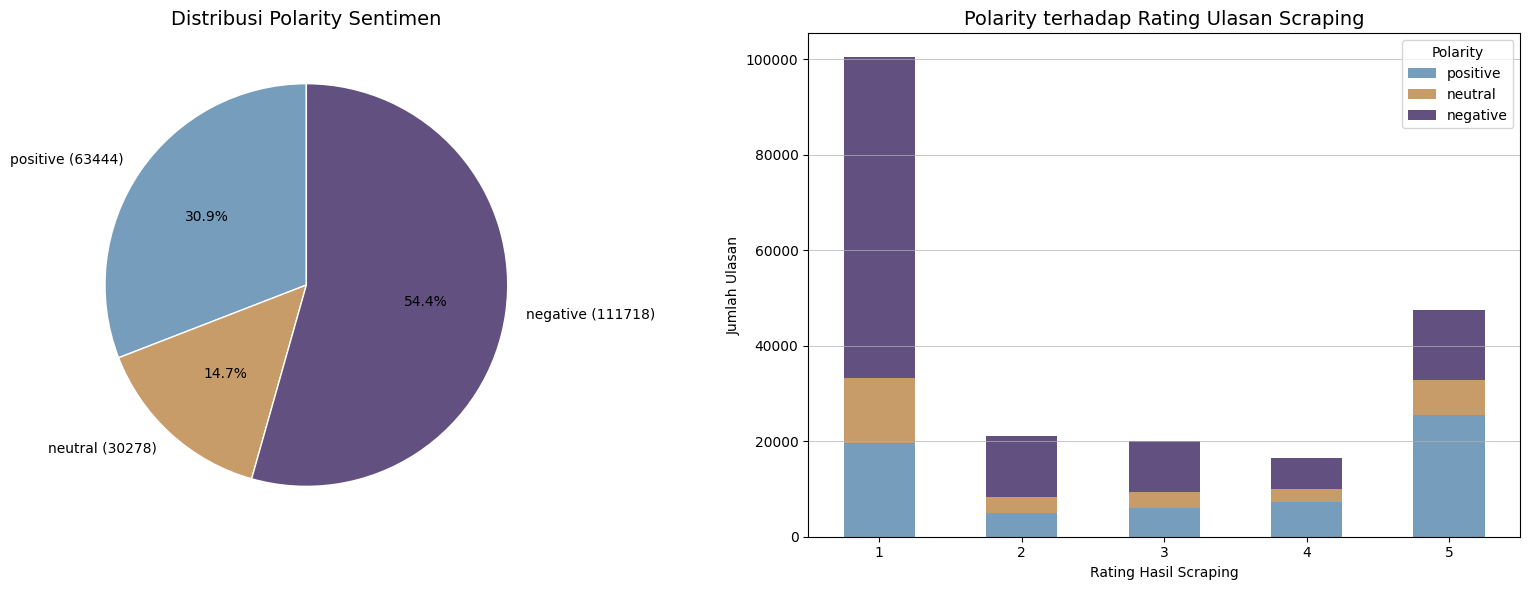

polarity,positive,neutral,negative
score,,,
1,19551,13733,67095
2,5068,3331,12721
3,6057,3318,10687
4,7231,2665,6582
5,25537,7231,14633


In [39]:
sentiment_label = ['positive', 'neutral', 'negative']
chart_color = {'positive': '#769DBB', 'neutral': "#C89C69", 'negative': '#625080'}

fig, ax = plt.subplots(1, 2, figsize=(16, 6))

# Visualisasi distribusi polaritas sentimen
hitung = df_clean['polarity'].value_counts().reindex(sentiment_label)

ax[0].pie(
    hitung.values,
    labels=[f'{k} ({v})' for k, v in zip(hitung.index, hitung.values)],
    colors=[chart_color[k] for k in sentiment_label],
    autopct='%1.1f%%',        # tampilkan persentase
    startangle=90,
    wedgeprops={'edgecolor': 'white'}
)
ax[0].set_title('Distribusi Polarity Sentimen', fontsize=14)

# Visualisasi perbandingan 'score' ulasan hasil scraping terhadap polaritas sentimen
tabel = pd.crosstab(df_clean['score'], df_clean['polarity'])[sentiment_label]

tabel.plot(kind='bar', stacked=True, color=[chart_color[k] for k in sentiment_label], ax=ax[1])
ax[1].set_title('Polarity terhadap Rating Ulasan Scraping', fontsize=14)
ax[1].set_xlabel('Rating Hasil Scraping')
ax[1].set_ylabel('Jumlah Ulasan')
ax[1].tick_params(axis='x', rotation=0)
ax[1].legend(title='Polarity')
ax[1].yaxis.grid(linewidth=0.5)

plt.tight_layout()
plt.show()
 # ringkasan
display(tabel)


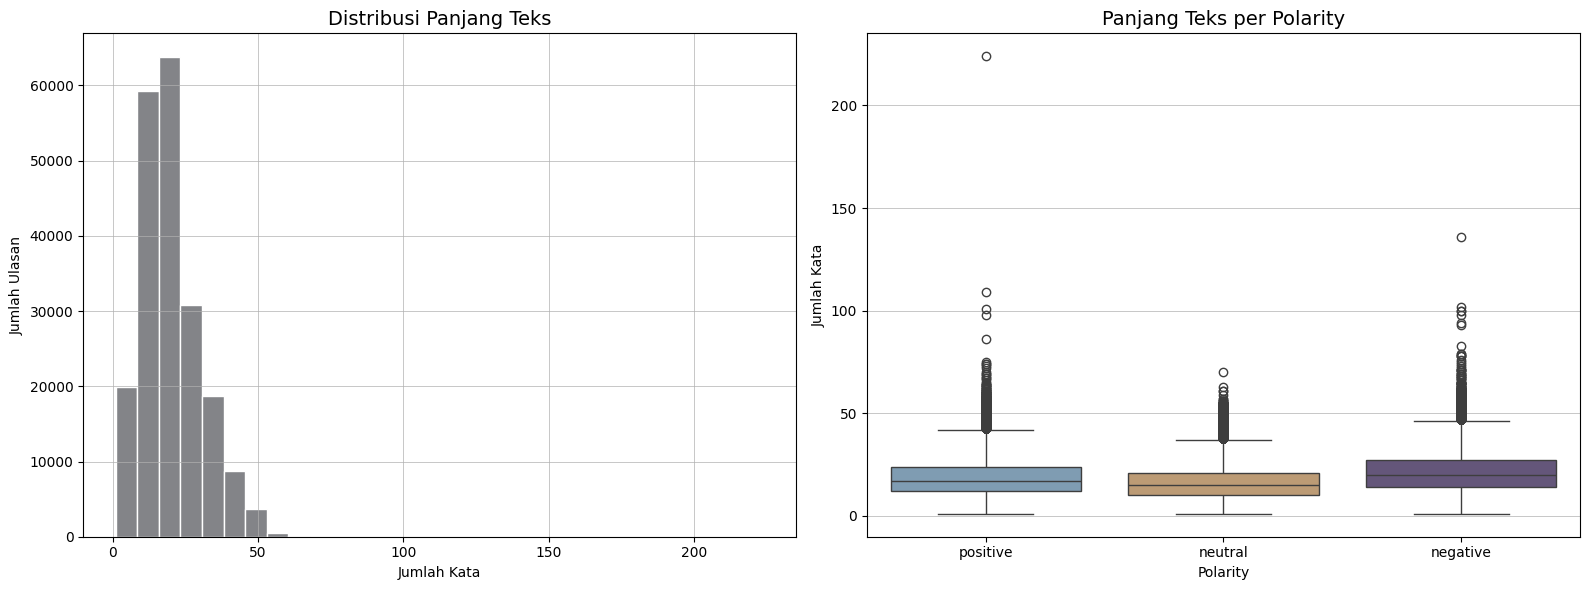

,count,mean,std,min,25%,50%,75%,max
polarity,,,,,,,,
negative,111718.0,21.5,10.4,1.0,14.0,20.0,27.0,136.0
neutral,30278.0,16.8,9.2,1.0,10.0,15.0,21.0,70.0
positive,63444.0,18.8,10.0,1.0,12.0,17.0,24.0,224.0


In [40]:
df_clean['txt_length'] = df_clean['text_final'].str.split().str.len()

fig, ax = plt.subplots(1, 2, figsize=(16, 6))

# Visualisasi ditribusi panjang ulasan
ax[0].hist(df_clean['txt_length'], bins=30, color="#838488", edgecolor='white')
ax[0].set_title('Distribusi Panjang Teks', fontsize=14)
ax[0].set_xlabel('Jumlah Kata')
ax[0].set_ylabel('Jumlah Ulasan')
ax[0].grid(linewidth=0.5)

# Visualisasi distribusi panjang ulasan per polarity
sns.boxplot(data=df_clean, x='polarity', y='txt_length', 
            palette=chart_color, hue='polarity',
            order=sentiment_label, ax=ax[1])
ax[1].set_title('Panjang Teks per Polarity', fontsize=14)
ax[1].set_xlabel('Polarity')
ax[1].set_ylabel('Jumlah Kata')
ax[1].yaxis.grid(linewidth=0.5)

plt.tight_layout()
plt.show()

# ringkasan
display(df_clean.groupby('polarity')['txt_length'].describe().round(1))


### ANALISIS
> **Temuan 1**: Berdasarkan 206.364 ulasan bersih terkait aplikasi MLBB dari GooglePlay Store, didapati sentimen "negatif (negative)" mendominasi dengan **54,4%** (112.306 ulasan), diikuti positif 30.9% (63.801 ulasan) dan netral 14,7% (30.257 ulasan). Dominasi ulasan negatif sejalan dengan rating `score` **1** (62.463 ulasan negatif) dari data yang paling tinggi dibandingkan dengan rating lainnya.

- **Rating 1-3**: dominan ulasan negatif dibandingkan positif
- **Rating 4-5**: dominan ulasan positif dibangingkan negatif

Hubungan antara sentimen dengan rating ulasan dapat dikatakan searah dimana rating rendah sejalan dengan sentimen negatif, sementara rating tinggi lebih mengarah pada sentimen positif. Namun, rating 3 yang seharushnya bisa didominasi netral, tidak begitu kentara dan cenderung masih lebih bnayak ulasan negatifnya.

> **Temuan 2**: Berdasarkan visual distribusi panjang teks ulasan bersih `text_final`, dapat diketahui bahwa banyak kata ulasan berada di sekitar 1-224 kata. Ulasan dengan banyak kata sekitar 20-30 kata memiliki frekuensi yang cukup tinggi. Lewat visual *box plot* terlihat bahwa ulasan negatif memiliki median 20 kata, lebih panjnag dari positif (17 kata) dan netral (15 kata). 

- **Ulasan bersih negatif**: terpanjang dengan 136 kata (terpendek 1 kata), rata-rata paling panjang dari ulasan positif dan netral.
- **Ulasan bersih positif**: terpanjang 224 kata (terpendek 1 kata), rata-rata lebih panjang dari ulasan netral.
- **Ulasan bersih netral**: terpanjang 70 kata (terpendek 1 kata), rata-rata paling pendek dari ulasan negatif dan positif.

Pengguna yang menyampaikan keluhan dalam ulasan negatif kemungkanan menjelaskan masalahnya lebih rinci. Lalu, karena perbedaan kecil panjang teks tiap sentimen, kemungkinan model belajar dari panjang teks sebagai petunjuk sentimen menjadi lebih rendah.

In [41]:
sampel = df_clean.groupby('polarity').sample(5, random_state=42)
display(sampel[['polarity', 'polarity_score', 'score', 'text_final']].sort_values('polarity'))


,polarity,polarity_score,score,text_final
88308,negative,-10,1,mengecewakan game main mlbb parah iyah jaringa...
96724,negative,-17,1,jelek game tiba² lag jaringan bagus dark siste...
85109,negative,-1,1,parah pembaruan asik main force closed gitu co...
130027,negative,-5,1,min tolong bantu game skrg makan jaringan main...
133826,negative,-3,1,game sistem mantap kali solo ketemu team tolol...
75778,neutral,0,2,tingkatkn kualitas pengamanannya player chead ...
71982,neutral,0,3,dark sistem tidak seimbang mobile legend segi ...
12976,neutral,0,5,jangan donwload kebanyakan bot sepi game emosi...
151317,neutral,2,2,tolong tolonglah hp ram passan suka force clos...
14465,neutral,0,1,iya jaringan lag jaringan oke main jalan


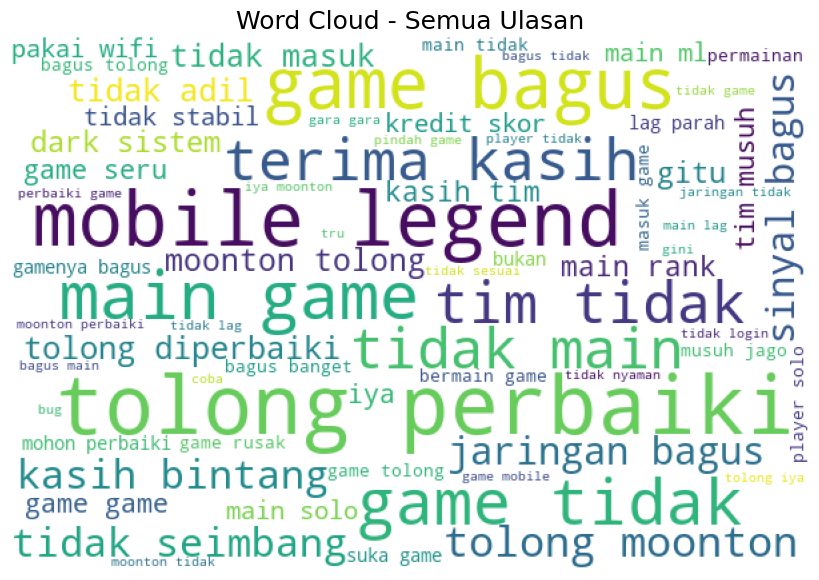

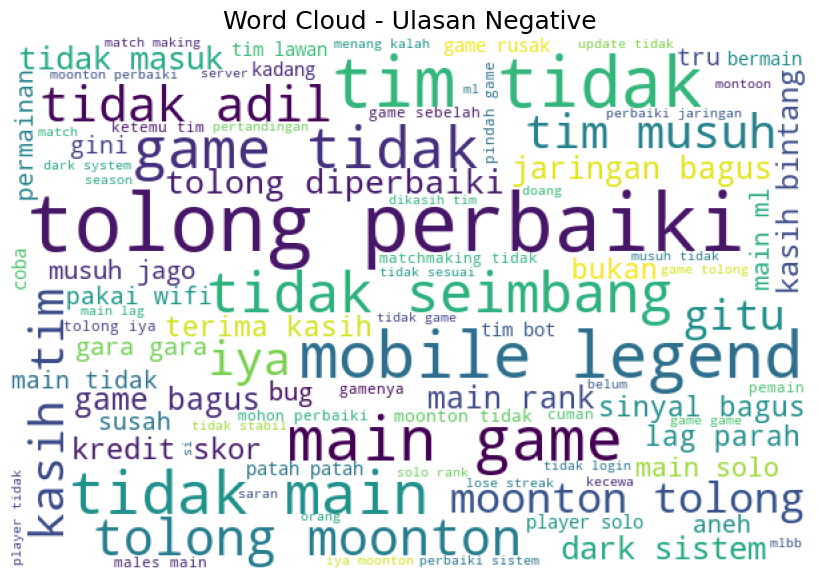

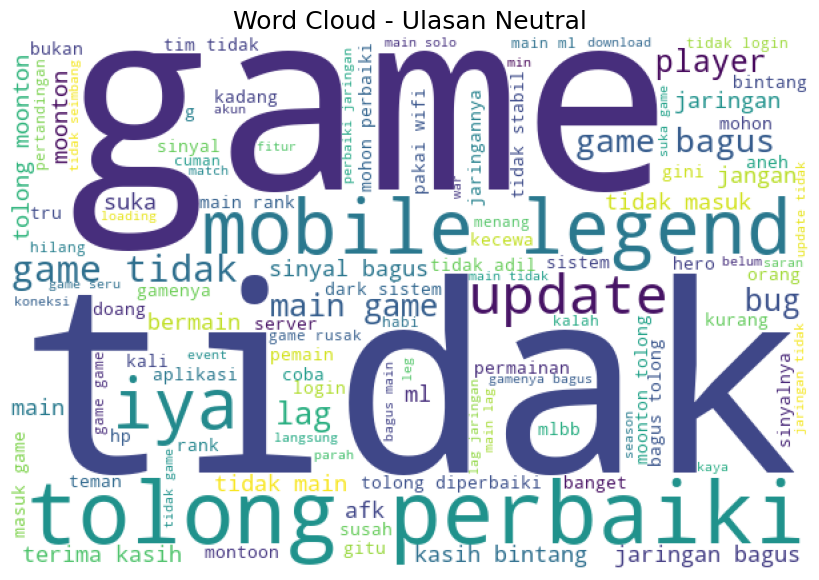

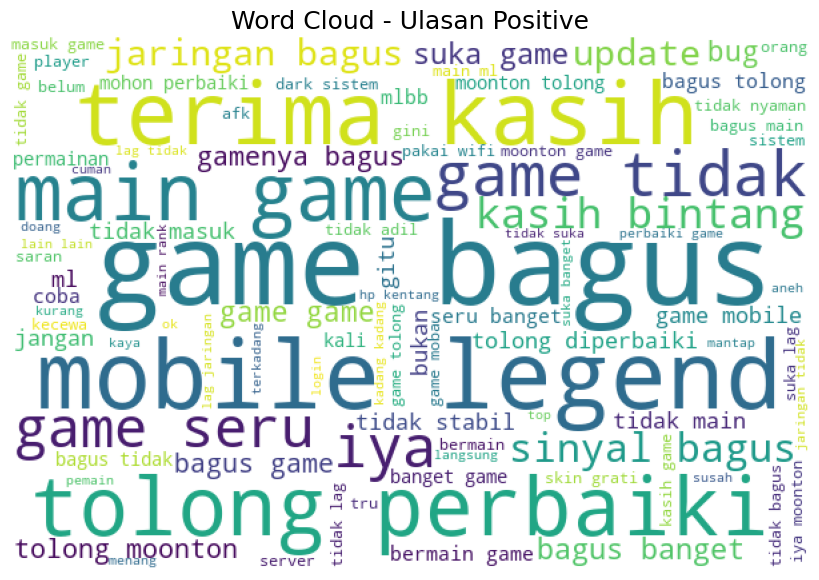

In [42]:
def plot_wordcloud(token_lists, title):
    words = ' '.join(' '.join(t) for t in token_lists)
    if not words.strip():
        print(f'Tidak ada kata untuk: {title}')
        return

    wc = WordCloud(width=600, height=400, background_color='white', min_font_size=10, ).generate(words)
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.set_title(title, fontsize=18)
    ax.imshow(wc)
    ax.axis('off')
    fig.tight_layout(pad=0)
    plt.show()

plot_wordcloud(df_clean['text_stopwords'], 'Word Cloud - Semua Ulasan')
for label in sorted(df_clean['polarity'].unique()):
    plot_wordcloud(df_clean.loc[df_clean['polarity'] == label, 'text_stopwords'],
                   f'Word Cloud - Ulasan {label.capitalize()}')


## 07. SPLIT DATA

In [43]:
X = df_clean['text_final']
y = df_clean['polarity']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

print(f'Ukuran data split:\n Data latih: {X_train.shape}\n Data uji  : {X_test.shape}')

data_model = pd.DataFrame({
    "Clean": y.value_counts(),
    "Train": y_train.value_counts(),
    "Test": y_test.value_counts()
}).reindex(sentiment_label)

display(data_model)


Ukuran data split:
 Data latih: (143808,)
 Data uji  : (61632,)


,Clean,Train,Test
polarity,,,
positive,63444,44411,19033
neutral,30278,21195,9083
negative,111718,78202,33516


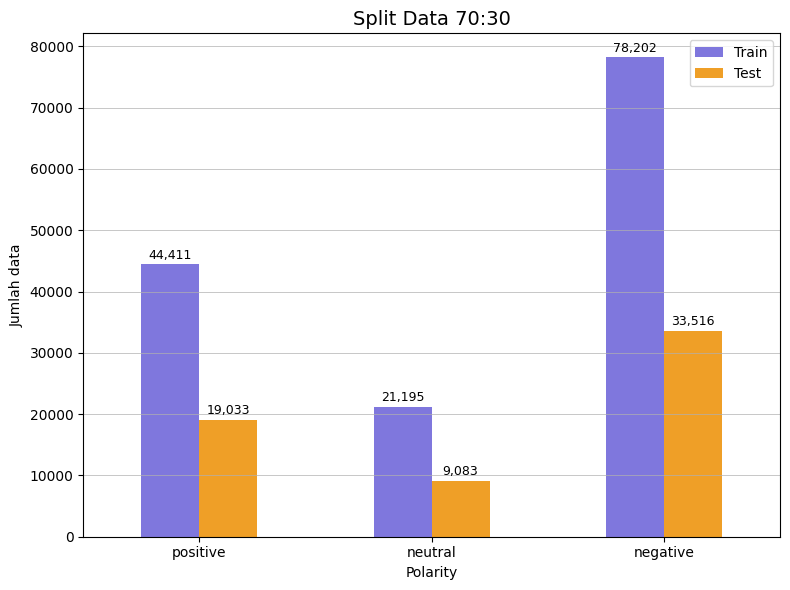

In [44]:
fig, ax = plt.subplots(figsize=(8, 6))

data_model[["Train", "Test"]].plot.bar(
    ax=ax, color=["#7F77DD", "#EF9F27"], rot=0
)
for c in ax.containers:
    ax.bar_label(c, fmt="{:,.0f}", fontsize=9, padding=2)
ax.set_xlabel("Polarity")
ax.set_ylabel("Jumlah data")
ax.set_title("Split Data 70:30", fontsize=14)
ax.legend()
ax.yaxis.grid(linewidth=0.5)

plt.tight_layout()
plt.show()


## 08. FEATURES EXTRACTION

In [45]:
# ekstrasi TF-IDF
tfidf = TfidfVectorizer(max_features=1000)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

# ekstraksi Bag of Words (BOW)
bow = CountVectorizer(max_features=1000)
X_train_bow = bow.fit_transform(X_train)
X_test_bow = bow.transform(X_test)

features = {
    'TF-IDF': (X_train_tfidf, X_test_tfidf),
    'BoW':    (X_train_bow,   X_test_bow),
}

print(f"TF-IDF:\n Data latih: {X_train_tfidf.shape}\n Data uji  : {X_test_tfidf.shape}")
print(f"BoW:\n Data latih: {X_train_bow.shape}\n Data uji  : {X_test_bow.shape}")


TF-IDF:
 Data latih: (143808, 1000)
 Data uji  : (61632, 1000)
BoW:
 Data latih: (143808, 1000)
 Data uji  : (61632, 1000)


## 09. MODELING & EVALUATION

In [46]:
def buat_models():
    return {
        'Random Forest':       RandomForestClassifier(random_state=42, n_jobs=-1),
        'Logistic Regression': LogisticRegression(max_iter=1000),
        'Decision Tree':       DecisionTreeClassifier(random_state=42),
    }

rows, test_preds = [], {}

for feat_name, (Xtr, Xte) in features.items():
    for name, model in buat_models().items():
        mulai = time.time()
        model.fit(Xtr, y_train)
        durasi = time.time() - mulai

        pred_train = model.predict(Xtr)
        pred_test = model.predict(Xte)
        test_preds[(feat_name, name)] = pred_test

        acc_train = accuracy_score(y_train, pred_train)
        acc_test = accuracy_score(y_test, pred_test)

        rows.append({
            'Fitur': feat_name,
            'Model': name,
            'Accuracy Train': acc_train,
            'Accuracy Test': acc_test,
            'Selisih': acc_train - acc_test,
            'Precision (macro)': precision_score(y_test, pred_test, average='macro', zero_division=0),
            'Recall (macro)': recall_score(y_test, pred_test, average='macro', zero_division=0),
            'F1 (macro)': f1_score(y_test, pred_test, average='macro', zero_division=0),
            'Waktu Latih (detik)': durasi,
        })

results_df = pd.DataFrame(rows).sort_values('F1 (macro)', ascending=False).reset_index(drop=True)
results_df.round(4)


,Fitur,Model,Accuracy Train,Accuracy Test,Selisih,Precision (macro),Recall (macro),F1 (macro),Waktu Latih (detik)
0,BoW,Logistic Regression,0.8816,0.8717,0.0099,0.8231,0.7897,0.8016,6.9770
1,TF-IDF,Logistic Regression,0.8613,0.8535,0.0078,0.8060,0.7399,0.7526,3.8826
2,BoW,Random Forest,0.9990,0.7642,0.2348,0.7022,0.6220,0.6266,239.0871
3,TF-IDF,Random Forest,0.9990,0.7625,0.2366,0.7176,0.6099,0.6101,248.3872
4,BoW,Decision Tree,0.9990,0.6720,0.3270,0.5782,0.5772,0.5777,119.9258
5,TF-IDF,Decision Tree,0.9990,0.6625,0.3365,0.5655,0.5638,0.5646,145.9924
